In [1]:
from get_lightcurves import read_catalog, lightcurve_url, download, CATALOG, ARCHIVE, LC_DIR

Group 1: 2,000 light curves
  number  index  kepler_bonus_id                gaia_id
       1      1  gaia-dr3-2076527425323873024   Gaia DR3 2076527425323873024
       2      2  kic-008285648                  Gaia DR3 2105917852162499456
       3      3  kic-007670498                  Gaia DR3 2105616173660012288
       4      4  gaia-dr3-2051754741152393728   Gaia DR3 2051754741152393728
       5      5  gaia-dr3-2077836359553252992   Gaia DR3 2077836359553252992
       6      6  gaia-dr3-2086876269277888384   Gaia DR3 2086876269277888384
       7      7  kic-011362232                  Gaia DR3 2086829471313707648
       8      8  gaia-dr3-2105745950391542400   Gaia DR3 2105745950391542400
       9      9  gaia-dr3-2130901780003112576   Gaia DR3 2130901780003112576
      10     10  kic-007770251                  Gaia DR3 2078755448196158848
      11     11  kic-011357021                  Gaia DR3 2134806180154711168
      12     12  kic-008054579                  Gaia DR3 207600680657

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightkurve as lk
import glob
from astropy.io import fits
from astropy.time import Time

/home/dasshamik300/.local/lib/python3.13/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [3]:
files = sorted(LC_DIR.glob("*.fits"))

# Testing On One File

In [4]:
# Testing on One
file = files[0]

In [5]:
with fits.open(file) as f:
    data = f["LIGHTCURVE_STITCHED"].data
    time = np.array(data["TIME"])
    flux = np.array(data["FLUX"])

mask = np.isfinite(time) & np.isfinite(flux)
time = time[mask]
flux = flux[mask]
time = Time(time, format="jd", scale="tdb")

In [6]:
lc = lk.LightCurve(time = time, flux = flux).normalize()

In [7]:
# Remove Long Term Trends + Sigmaclip
window_length = 101
lc_flat = lc.flatten(window_length = window_length).remove_outliers(sigma_lower = float("inf"), sigma_upper = 3)

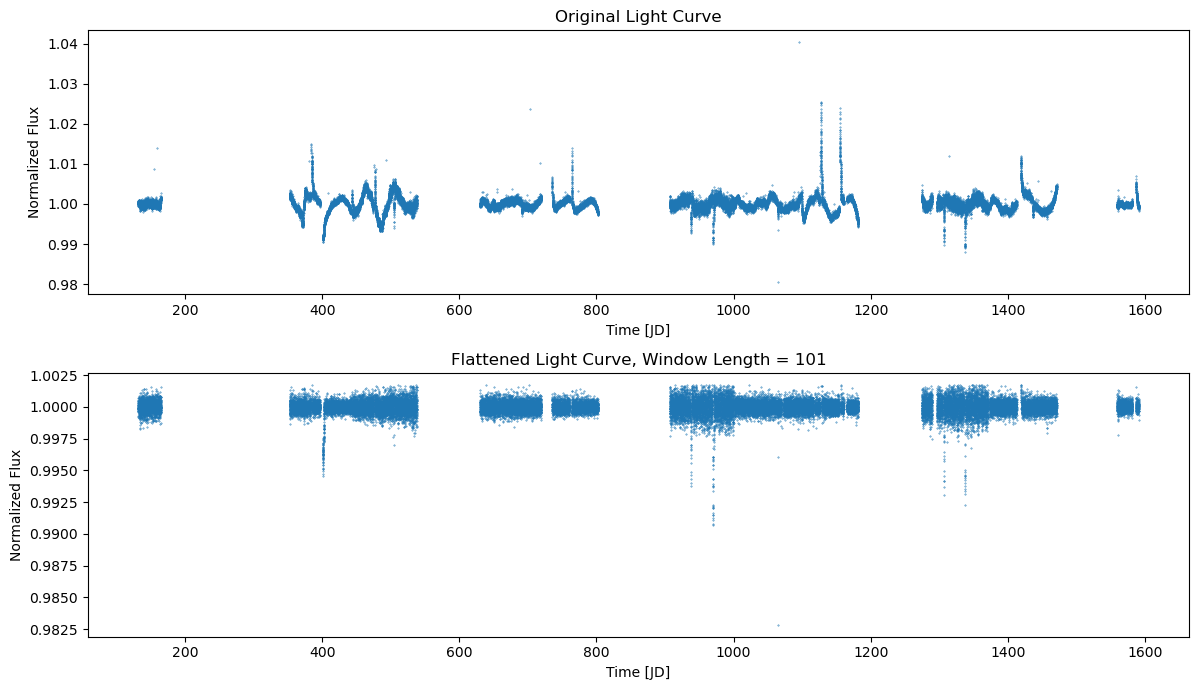

In [8]:
# Compare
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

lc.scatter(ax = axes[0], s = 0.5)
lc_flat.scatter(ax = axes[1], s = 0.5)

axes[0].set_title("Original Light Curve")
axes[1].set_title(f"Flattened Light Curve, Window Length = {window_length}")

plt.tight_layout()
plt.show()

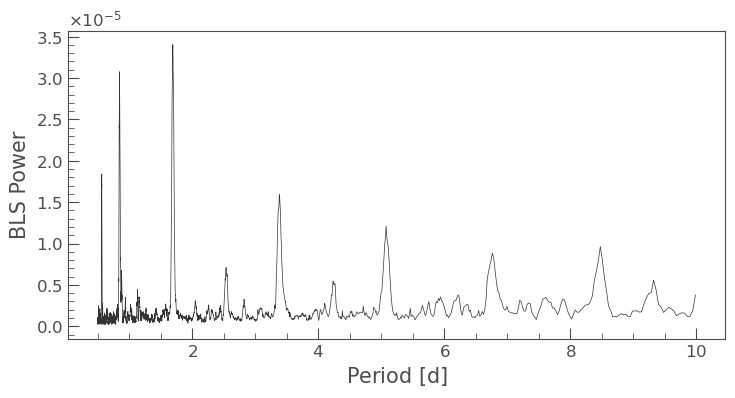

In [9]:
# First 180 days
trial_lc = lc_flat[lc_flat.time.jd < lc_flat.time.jd.min() + 180]

# Run Box Least Squares
bls = trial_lc.to_periodogram(
    method="bls",
    minimum_period=0.5, # Days
    maximum_period=10,
    duration=[0.05, 0.10, 0.20, 0.40], # Transit Durration (Days)
    frequency_factor=10
)

# Plot periodogram
bls.plot()
plt.show()

In [10]:
best_period = bls.period_at_max_power
best_t0 = bls.transit_time_at_max_power
best_duration = bls.duration_at_max_power
best_depth = bls.depth_at_max_power

print(f"Best Period: {best_period:.5f}")
print(f"Duration: {best_duration:.5f}")
print(f"Depth: {best_depth:.5f}")

Best Period: 1.69185 d
Duration: 0.20000 d
Depth: 0.00060


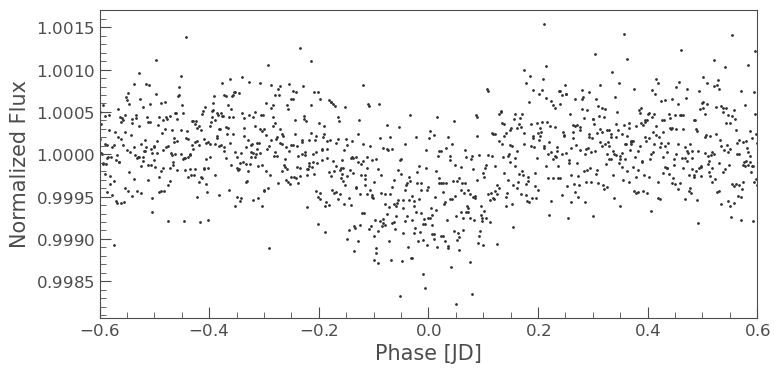

In [11]:
folded_lc = trial_lc.fold(period = best_period, epoch_time = best_t0)

ax = folded_lc.scatter()
ax.set_xlim(-3 * best_duration.value, 3 * best_duration.value)

plt.show()

# Going through all

In [12]:
def run_bls(file):
    
    with fits.open(file) as f:
        data = f["LIGHTCURVE_STITCHED"].data
        time = np.array(data["TIME"])
        flux = np.array(data["FLUX"])

    mask = np.isfinite(time) & np.isfinite(flux)
    time = time[mask]
    flux = flux[mask]
    time = Time(time, format="jd", scale="tdb")
    
    lc = lk.LightCurve(time = time, flux = flux).normalize()

    # Remove Long Term Trends + Sigmaclip
    window_length = 101
    lc_flat = lc.flatten(window_length = window_length).remove_outliers(sigma_lower = float("inf"), sigma_upper = 3)

    # First 90 days
    trial_lc = lc_flat[lc_flat.time.jd < lc_flat.time.jd.min() + 90]

    # Run Box Least Squares
    bls = trial_lc.to_periodogram(
        method = "bls",
        minimum_period = 0.5, # Days
        maximum_period = 10,
        duration = [0.05, 0.10, 0.20, 0.40], # Transit Durration (Days)
        frequency_factor = 10
    )

    best_period = bls.period_at_max_power
    best_t0 = bls.transit_time_at_max_power
    best_duration = bls.duration_at_max_power
    best_depth = bls.depth_at_max_power

    folded_lc = trial_lc.fold(period = best_period, epoch_time = best_t0)
    
    results = {
        "file": file.name,
        "period": bls.period_at_max_power.value,
        "t0": bls.transit_time_at_max_power,
        "duration": bls.duration_at_max_power.value,
        "depth": bls.depth_at_max_power.value,
        "power": np.max(bls.power.value),
        "folded_lc": folded_lc
    }

    return results

In [13]:
results = []
i = 0
for file in files:
    print(i)
    i = i + 1
    try:
        results.append(run_bls(file))
    except Exception as e:
        print(f"Failed: {file.name}: {e}")

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99


In [14]:
bls_results = pd.DataFrame(results)
bls_results = bls_results.sort_values("power", ascending=False)

In [15]:
bls_results.head(10)

,file,period,t0,duration,depth,power,folded_lc
17,hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2086448...,2.045238,122.13837645240127,0.2,0.186057,6.542667,"[[-1.0224790004243731, 0.9710414966446295, nan..."
25,hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2104247...,9.876780,121.08952198615297,0.4,0.038933,0.127327,"[[-4.9368414975399615, 1.0071993051559545, nan..."
54,hlsp_kbonus-bkg_kepler_kepler_kic-006374056_ke...,1.058068,131.80723507151006,0.4,0.011129,0.094632,"[[-0.528962554248694, 1.0107625244055365, nan,..."
20,hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2101572...,7.693411,123.61418590629474,0.4,0.027330,0.072450,"[[-3.8410971177620263, 1.0036872202724416, nan..."
85,hlsp_kbonus-bkg_kepler_kepler_kic-009457723_ke...,8.297439,125.84908982407302,0.4,0.026038,0.065427,"[[-4.148506020090754, 0.999879404508614, nan, ..."
30,hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2117308...,7.671680,138.04794293394312,0.4,0.027434,0.064347,"[[-3.834940383675394, 1.0067765975763072, nan,..."
23,hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2103428...,8.652723,122.64972632577643,0.4,0.027387,0.058130,"[[-4.326228221913666, 0.8130328249348983, nan,..."
95,hlsp_kbonus-bkg_kepler_kepler_kic-010583170_ke...,2.697375,122.19434511868283,0.2,0.020388,0.055910,"[[-1.3486855062071226, 0.9896500188141633, nan..."
34,hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2130851...,6.292751,125.0190614583157,0.4,0.019279,0.036238,"[[-3.1457727640365825, 0.9967427820475857, nan..."
33,hlsp_kbonus-bkg_kepler_kepler_gaia-dr3-2127024...,1.696008,121.01038342000916,0.4,0.009320,0.035918,"[[-0.8390756653075255, 0.9809224905557893, nan..."


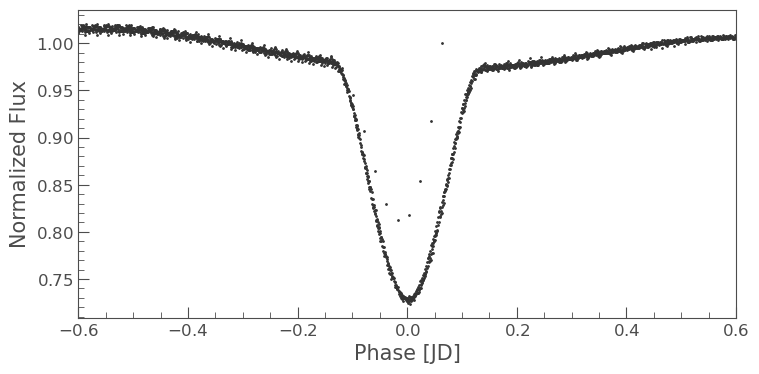

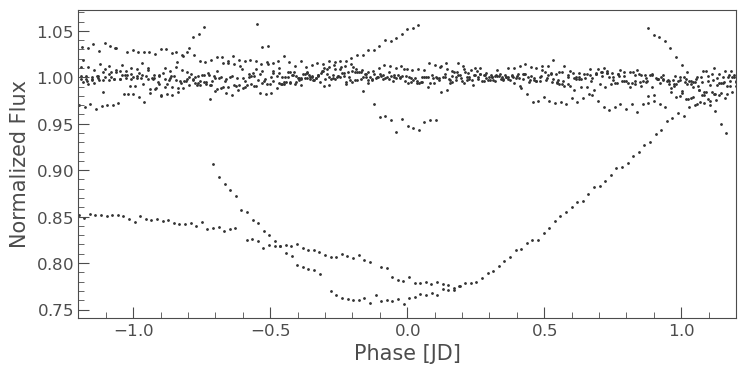

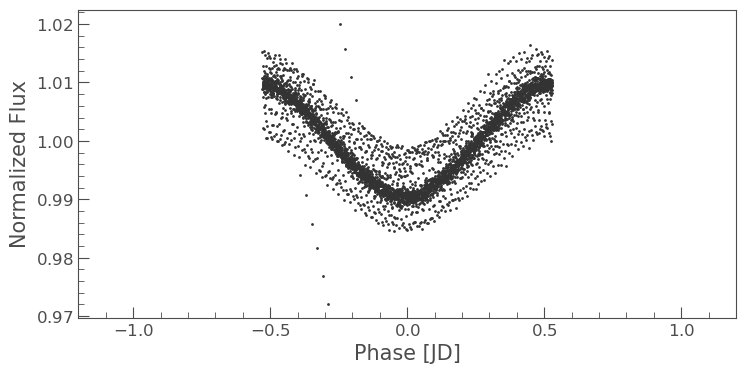

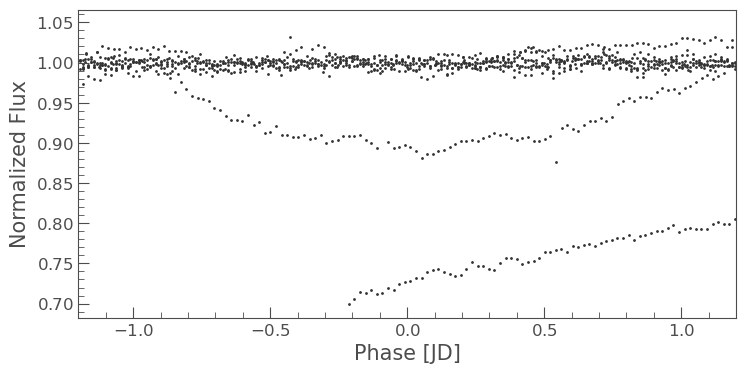

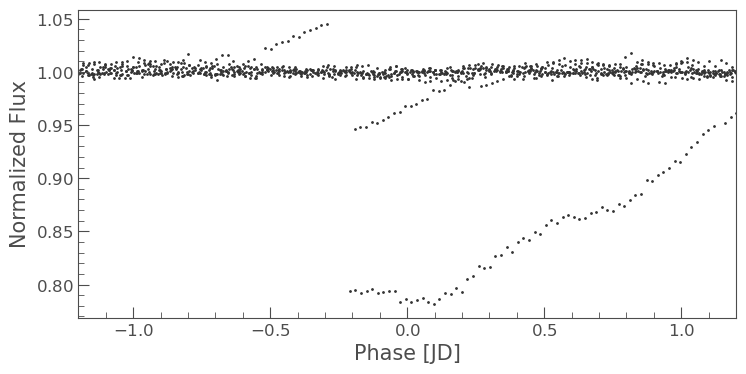

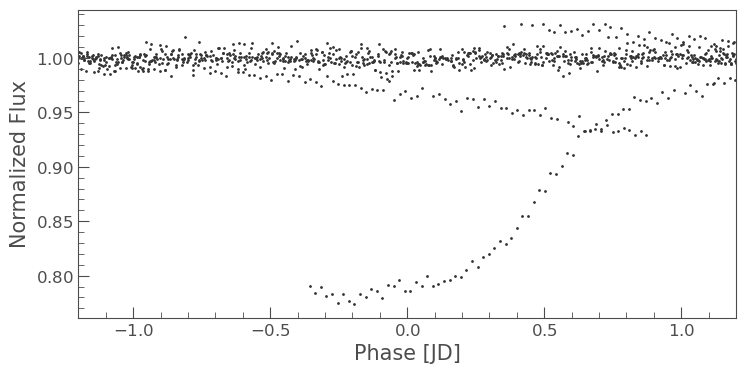

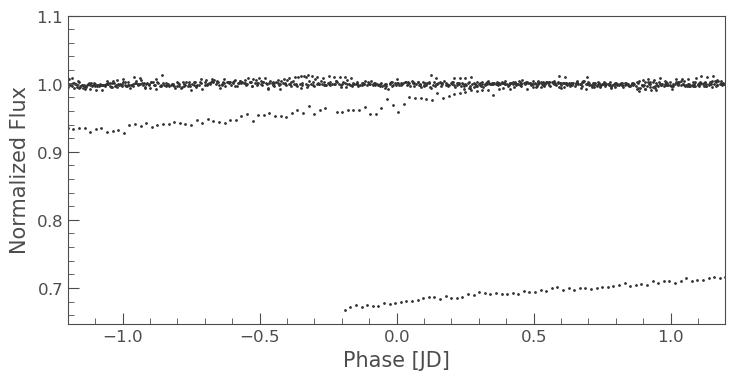

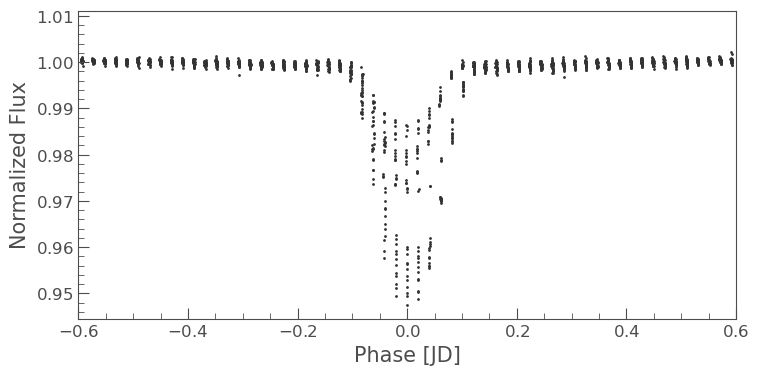

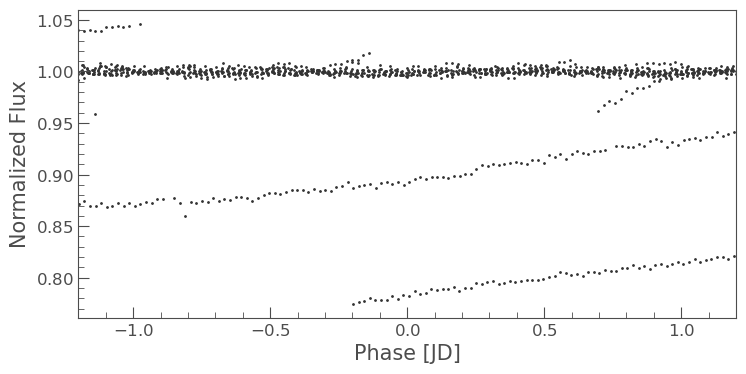

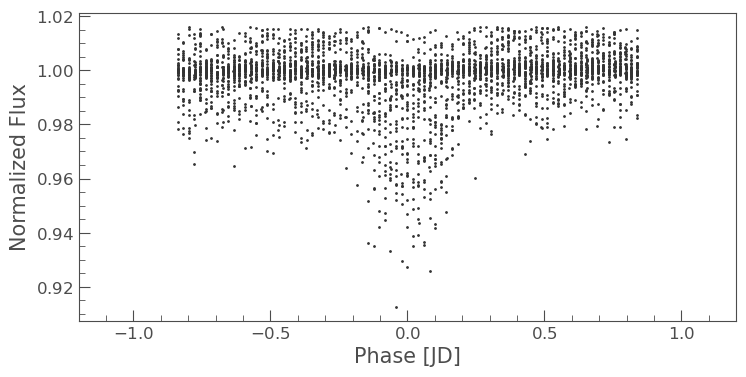

In [19]:
for folded_lc, best_duration in zip(bls_results['folded_lc'][0:10], bls_results['duration'][0:10]):

    ax = folded_lc.scatter()
    ax.set_xlim(-3 * best_duration, 3 * best_duration)
    
    plt.show()